# D08 · A better reranker can worsen the pipeline
Compare complete retrieval pipelines and fixed candidate pools, plot held-out rank changes, and inspect a query without loading embedding models.
**Prerequisites:** basic Python and the [learning guide](../docs/LEARNING_GUIDE.md).
**Evidence boundary:** the charts read the recorded October 26, 2026 experiments by default. Running this notebook recomputes plots and teaching calculations; it does not retrain a model or run new model inference. Illustrative examples below are labeled separately. The [notebook guide](README.md) explains setup, provenance, and how to export your own completed runs.

## Load the evidence
Run all cells in order. The loader prints the run IDs, dates, seeds and scope. A custom export does not automatically rewrite the historical interpretation in this lesson.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# Works when Jupyter starts in the repository root or notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/lab.py").is_file() and (p / "src/ml_training").is_dir())
for folder in [ROOT / "notebooks", ROOT / "src"]:
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))
from lab import load_demo, style, grouped_bars
style()

# None uses the compact checked-in snapshot. To inspect a new export, set an
# explicit path, e.g. ROOT / "artifacts/my-notebook-results.json". Missing files fail.
SNAPSHOT_PATH = None
d = load_demo("D08", SNAPSHOT_PATH)

Matplotlib is building the font cache; this may take a moment.


D08 | recorded experiment data | recorded_results.json
Recorded local educational experiments. Inspect run dates, seeds and source manifests before comparing results. No production or physical-device validation.
Run: artifacts/retrieval/local-s41-20261026T165108Z-bcab85 | recorded: 20261026T165108Z | seed: 41


## The concept
A bi-encoder independently embeds queries and documents for candidate search. A cross-encoder jointly scores each query/document pair and can only reorder candidates it receives. If the relevant document is absent, reranking cannot recover it.
Recall@k asks whether relevant evidence is in the shortlist. Reciprocal rank rewards early placement; MRR@10 averages $1/r$ when rank $r \leq 10$, otherwise zero. Fixed-pool comparisons isolate ranking changes; full-pipeline comparisons include candidate quality.

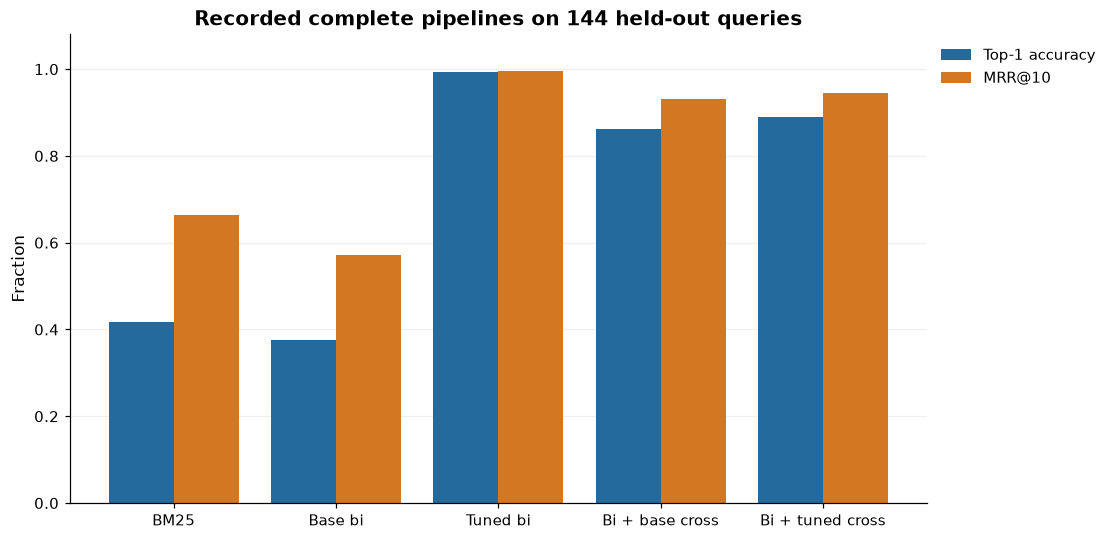

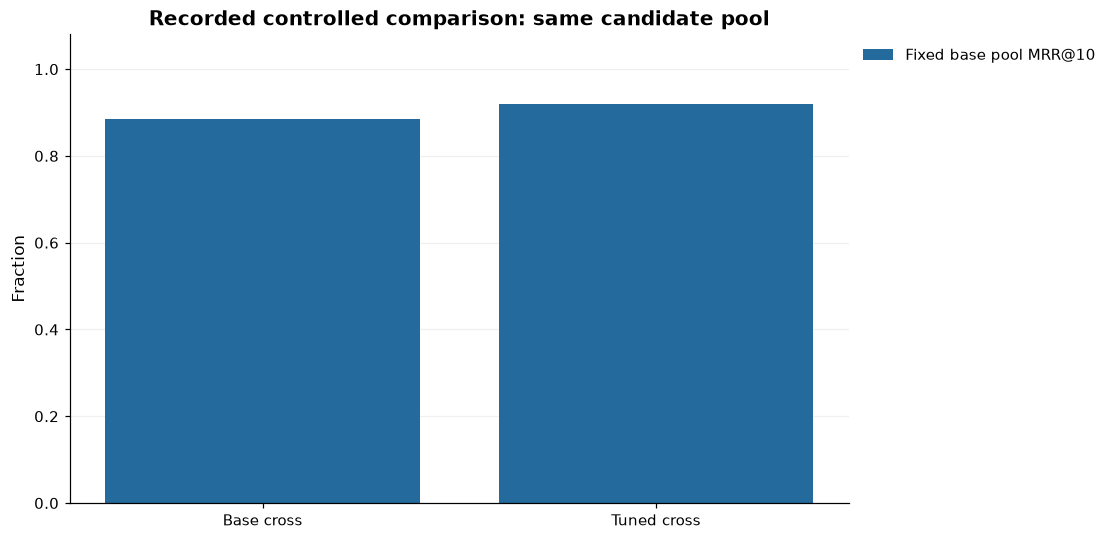

In [2]:
variants = ['bm25', 'base_bi', 'tuned_bi', 'tuned_bi_base_cross', 'tuned_bi_tuned_cross']
labels = ['BM25', 'Base bi', 'Tuned bi', 'Bi + base cross', 'Bi + tuned cross']
grouped_bars(labels, {
    'Top-1 accuracy': [d['metrics'][v]['top1_accuracy'] for v in variants],
    'MRR@10': [d['metrics'][v]['mrr_at_10'] for v in variants],
}, title='Recorded complete pipelines on 144 held-out queries')
plt.show()
grouped_bars(['Base cross', 'Tuned cross'], {
    'Fixed base pool MRR@10': [d['metrics'][v]['mrr_at_10'] for v in ['fixed_base_pool_base_cross', 'fixed_base_pool_tuned_cross']],
}, title='Recorded controlled comparison: same candidate pool')
plt.show()

### Inspect every query, then choose one
The following matrix contains **all 144 held-out queries**, sorted by ID, rather than a selected set of wins. Lower rank is better; a rank outside the displayed cutoff contributes zero to MRR@10. No scores or model inference are recomputed here.

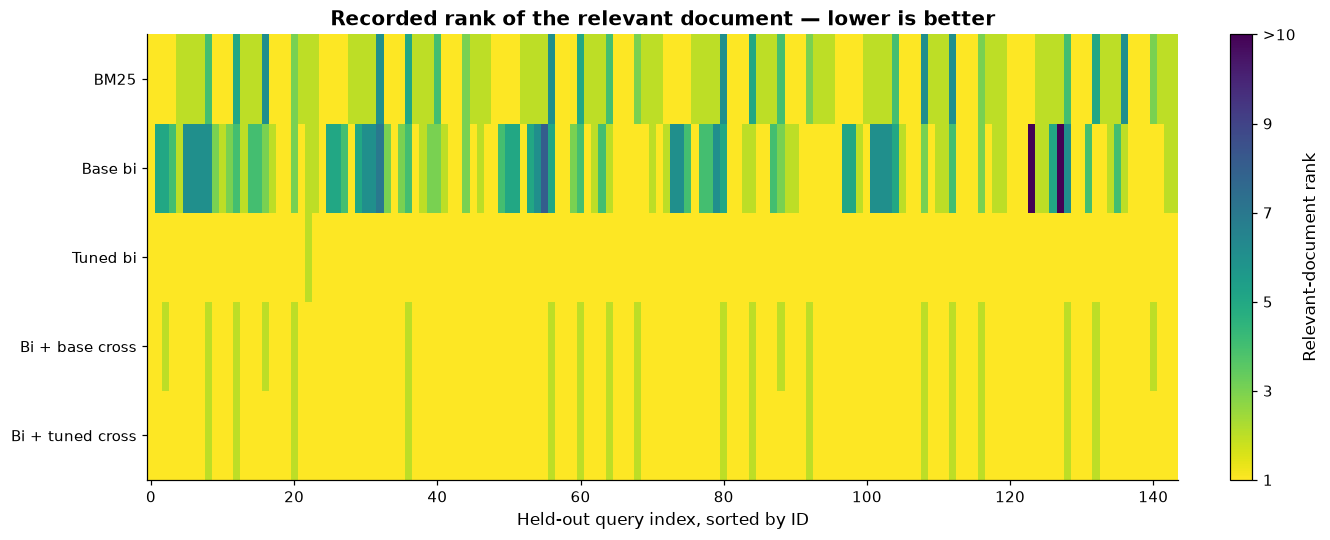

Query ID: audit-export-v2-read-q2
bm25                     rank=1, reciprocal rank@10=1.000
base_bi                  rank=2, reciprocal rank@10=0.500
tuned_bi                 rank=1, reciprocal rank@10=1.000
tuned_bi_base_cross      rank=1, reciprocal rank@10=1.000
tuned_bi_tuned_cross     rank=1, reciprocal rank@10=1.000


In [3]:
by_variant = {v: {r['query_id']: r['rank'] for r in d['ranks'] if r['variant'] == v} for v in variants}
query_ids = sorted(by_variant['tuned_bi'])
ranks = np.array([[by_variant[v][q] for q in query_ids] for v in variants], dtype=float)
fig, ax = plt.subplots(figsize=(12, 4.8), layout='constrained')
image = ax.imshow(np.minimum(ranks, 11), aspect='auto', cmap='viridis_r', vmin=1, vmax=11)
ax.set(yticks=np.arange(len(labels)), yticklabels=labels, xlabel='Held-out query index, sorted by ID',
       title='Recorded rank of the relevant document — lower is better')
colorbar = fig.colorbar(image, ax=ax, ticks=[1, 3, 5, 7, 9, 11], label='Relevant-document rank')
colorbar.ax.set_yticklabels(['1', '3', '5', '7', '9', '>10'])
plt.show()
query_index = 10  # Try another integer from 0 through 143.
query = query_ids[query_index]
print('Query ID:', query)
for v in variants:
    rank = by_variant[v][query]
    rr = 1/rank if rank <= 10 else 0
    print(f'{v:24s} rank={rank}, reciprocal rank@10={rr:.3f}')

**Interpretation check:** tuning the cross-encoder helps on the fixed base pool, yet the tuned bi-encoder alone wins the complete pipeline. These statements are compatible. The small synthetic corpus uses exact search and one neural seed. Try lexical/dense fusion or a different candidate pool on a new representative dataset before assuming a reranker helps.

## What you learned and when to use it
Inspect missing candidates, stale documents, version errors and ranking separately. Training cannot repair absent evidence or authorization mistakes. Compare BM25, hybrid retrieval and better chunking before accepting a heavier ranking pipeline.
**Architecture exercise:** state a quality floor, a simpler alternative, and the evidence that would make you reject this approach. Compare your answer with the [decision guide](../docs/ARCHITECTURE_DECISION_GUIDE.md#d08--improve-retrieval-and-ranking).
**Train or run the actual model:** follow the [D08 tutorial](../docs/RETRIEVAL_DEMO.md). Training stays in its existing locked environment; this notebook stays light enough to run without model downloads.
[All visual lessons](README.md) · [Production tradeoffs](../docs/PRODUCTION_TRADEOFFS.md)